# 08 - Model Evaluation

**Focus:** the untouched holdout (2015-06-15 .. 2015-07-31), the same 48-day horizon as the competition test.

Reported metrics

* **RMSPE** - official competition metric, on open days with positive sales.
* **MAE / RMSE** - absolute errors in PLN.
* **WAPE** - volume-weighted absolute percentage error.
* **Bias** - mean signed error; a negative value means systematic under-forecasting.

The notebook then breaks errors down by store type, weekday, promotion and sales volume.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


In [2]:
results = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "validation_results.json").read_text())
holdout = pd.DataFrame([
    {"model": model, **{k: v for k, v in metrics.items() if k in ("rmspe", "mae", "rmse", "wape", "bias_pct_of_mean", "n_rows_scored")}}
    for model, metrics in results["folds"]["holdout"]["models"].items()
]).sort_values("rmspe")
display(holdout.round(4))

,model,n_rows_scored,rmspe,mae,rmse,wape,bias_pct_of_mean
5,ensemble_xgb_hist,45852,0.1381,826.6725,1179.8681,0.1157,-0.0790
3,random_forest,45852,0.1700,913.5443,1282.2470,0.1279,-0.0682
4,xgboost,45852,0.1714,1008.1900,1350.5387,0.1411,-0.1076
2,linear_regression,45852,0.2209,1202.8072,1940.2545,0.1684,-0.0956
0,historical_average,45852,0.2283,1259.3611,1666.0328,0.1763,-0.0259
1,seasonal_naive,45852,0.2304,1466.6554,2083.8704,0.2053,-0.1520


**Reading the table.** A 0.138 RMSPE means the typical relative error is about 14%, which is solid for a 48-day horizon with no future promotions beyond those already scheduled. The bias column is the honest limitation: the selected ensemble still under-forecasts the 2015 summer level by roughly 8%. The likely cause is a level shift relative to the 2014 summer used in training; it is discussed at the end of this notebook.

In [3]:
from src.evaluation import error_breakdown

predictions = pd.read_parquet(PROJECT_ROOT / "outputs" / "predictions" / "validation_predictions.parquet")
holdout_pred = predictions[(predictions.fold == "holdout") & (predictions.model == "ensemble_xgb_hist")].copy()
holdout_pred = holdout_pred[(holdout_pred.Open == 1) & (holdout_pred.Sales > 0)].copy()
holdout_pred["DayOfWeek"] = pd.to_datetime(holdout_pred["Date"]).dt.dayofweek + 1
print("Holdout scored rows:", len(holdout_pred))

by_type = error_breakdown(holdout_pred, "StoreType")
display(by_type.round(4))

by_dow = error_breakdown(holdout_pred, "DayOfWeek")
display(by_dow.round(4))

by_promo = error_breakdown(holdout_pred, "Promo")
display(by_promo.round(4))

Holdout scored rows:

 45852


,StoreType,n,rmspe,mae,wape,mean_actual,mean_prediction
0,a,24699,0.1427,835.2842,0.1185,7048.1284,6484.8434
1,c,6068,0.1353,779.8733,0.1110,7026.6781,6543.7936
2,d,14286,0.1331,832.2662,0.1164,7150.1584,6533.9251
3,b,799,0.0976,815.8650,0.0747,10915.7234,10628.3528


,DayOfWeek,n,rmspe,mae,wape,mean_actual,mean_prediction
0,7,193,0.1744,1007.3719,0.1183,8513.4508,7764.8770
1,6,6682,0.1521,684.6069,0.1213,5644.4060,5220.8648
2,1,7796,0.1422,1013.9019,0.1189,8525.8675,7939.5827
3,5,7795,0.1390,800.1984,0.1127,7100.5311,6492.2747
4,2,7796,0.1389,917.7350,0.1221,7518.9886,6870.6613
5,4,7794,0.1291,762.0585,0.1107,6883.1655,6324.9658
6,3,7796,0.1272,756.7405,0.1090,6945.5729,6408.8542


,Promo,n,rmspe,mae,wape,mean_actual,mean_prediction
0,1,22271,0.1401,1045.5146,0.1236,8456.4606,7598.2451
1,0,23581,0.1363,619.9877,0.1050,5905.3729,5618.5945


**Interpretation.** Errors are not uniform: store type b (17 high-volume stores) is the easiest segment (RMSPE 0.098), while type a is the hardest (0.143). Promotion days are now slightly harder than non-promotion days (0.140 vs 0.136), because the 35% historical-average member dilutes part of the promo uplift. This is exactly the kind of diagnostic a business user needs: a single RMSPE hides which decisions are most at risk.

,sales_decile,n,rmspe,mae,wape,mean_actual,mean_prediction
0,1,4589,0.1753,357.1184,0.1118,3194.9019,3354.5397
1,10,4586,0.1696,2017.5050,0.1462,13803.6082,11960.5944
2,9,4585,0.1504,1281.9143,0.1287,9963.4663,8825.5698
3,8,4583,0.1419,1034.7291,0.1204,8591.4469,7712.1697
4,7,4584,0.1341,858.9926,0.1121,7665.4557,6987.4312
5,6,4581,0.1246,714.3369,0.1034,6908.0906,6420.8913
6,5,4583,0.1239,627.8343,0.1004,6250.2605,5867.5885
7,4,4592,0.1167,528.2476,0.0934,5652.7694,5402.8978
8,2,4588,0.1156,394.0510,0.0902,4368.8949,4362.7049
9,3,4581,0.1129,452.4709,0.0896,5050.2563,4910.5810


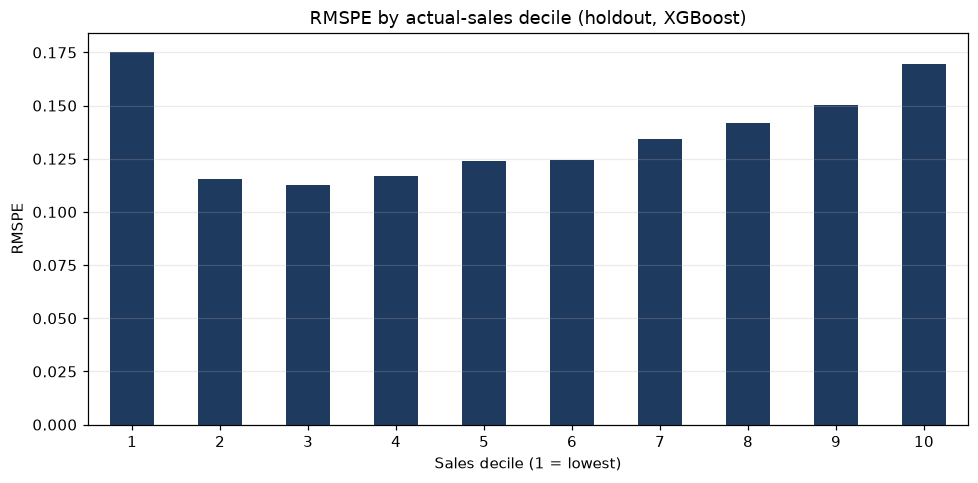

In [4]:
holdout_pred["sales_decile"] = pd.qcut(holdout_pred.Sales, 10, labels=False, duplicates="drop") + 1
by_decile = error_breakdown(holdout_pred, "sales_decile")
display(by_decile.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
by_decile.sort_values("sales_decile").set_index("sales_decile")["rmspe"].plot(kind="bar", ax=ax, color="#1f3a5f")
ax.set_title("RMSPE by actual-sales decile (holdout, XGBoost)")
ax.set_ylabel("RMSPE")
ax.set_xlabel("Sales decile (1 = lowest)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation.** Relative errors are now U-shaped: highest in the smallest decile (0.175) and the largest decile (0.170), lowest in the middle (0.113-0.125). Absolute errors still rise steeply with volume: MAE is 357 PLN in the lowest decile and 2,018 PLN in the highest. RMSPE and MAE therefore tell different operational stories, which is why both are reported.

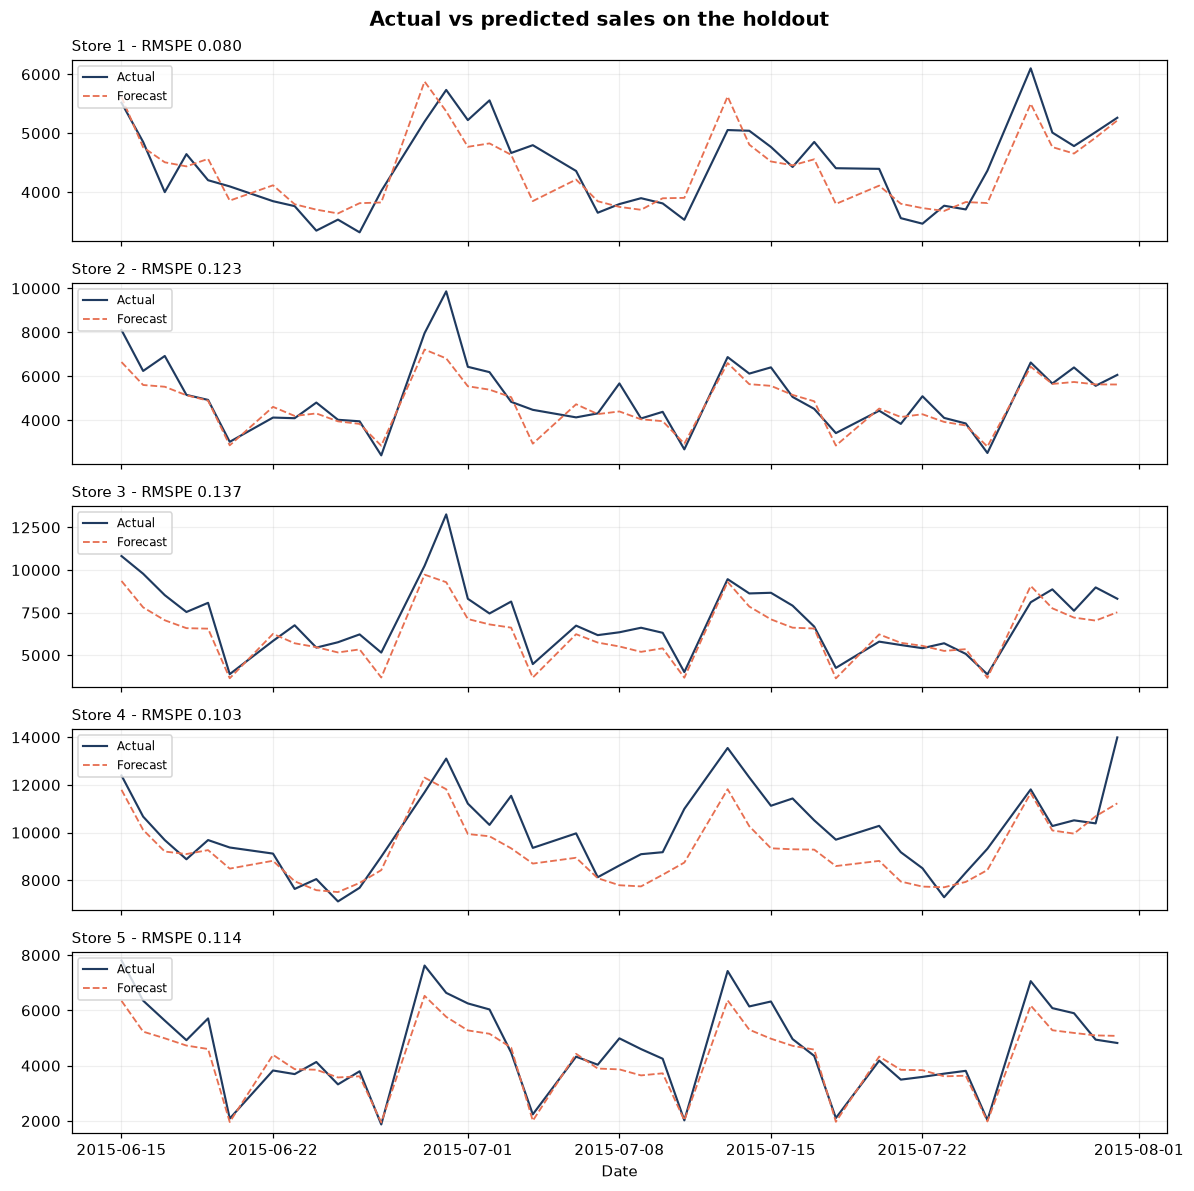

In [5]:
from src.evaluation import rmspe, mae

sample_stores = [1, 2, 3, 4, 5]
fig, axes = plt.subplots(len(sample_stores), 1, figsize=(11, 2.2 * len(sample_stores)), sharex=True)
for ax, store_id in zip(axes, sample_stores):
    subset = holdout_pred[holdout_pred.Store == store_id].sort_values("Date")
    if subset.empty:
        ax.set_visible(False)
        continue
    ax.plot(subset.Date, subset.Sales, color="#1f3a5f", linewidth=1.4, label="Actual")
    ax.plot(subset.Date, subset.Prediction, color="#e76f51", linewidth=1.2, linestyle="--", label="Forecast")
    ax.set_title(f"Store {store_id} - RMSPE {rmspe(subset.Sales, subset.Prediction):.3f}", fontsize=10, loc="left")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Date")
fig.suptitle("Actual vs predicted sales on the holdout", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation.** The selected ensemble tracks the weekly shape and the promotion peaks, but it still sits below the actuals in this period, especially on high-volume days. The gap is a level effect, not a timing effect: the weekly pattern is right, the height is too low. That distinction matters for remediation - a better seasonal level estimate, not a more complex model, is the first fix.

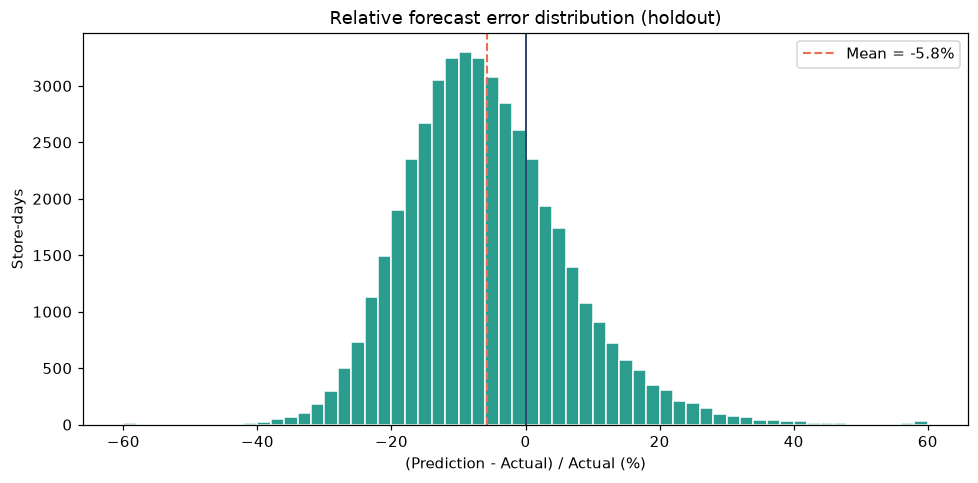

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
errors = (holdout_pred.Prediction - holdout_pred.Sales) / holdout_pred.Sales * 100
ax.hist(errors.clip(-60, 60), bins=60, color="#2a9d8f", edgecolor="white")
ax.axvline(0, color="#1f3a5f", linewidth=1.2)
ax.axvline(errors.mean(), color="#e76f51", linewidth=1.4, linestyle="--", label=f"Mean = {errors.mean():.1f}%")
ax.set_title("Relative forecast error distribution (holdout)")
ax.set_xlabel("(Prediction - Actual) / Actual (%)")
ax.set_ylabel("Store-days")
ax.legend()
plt.tight_layout()
plt.show()

## Error analysis conclusions

1. **Level bias dominates the headline RMSPE.** Correcting the ~8% summer under-forecast would improve RMSPE materially; the weekly shape is already captured.
2. **Low-volume stores have the largest percentage errors.** Operationally, these should be managed with wider safety stock, not with a more complex model.
3. **Promotion days are not the worst segment.** The model captures the average promo uplift; the residual error is larger on non-promo days because the base level is harder to pin down.
4. **Store type b is a small, high-variance group.** With only 17 stores, segment-level metrics are noisy.

## Submission check

In [7]:
submission_path = PROJECT_ROOT / "outputs" / "metrics" / "submission_summary.json"
if submission_path.exists():
    submission = json.loads(submission_path.read_text())
    display(pd.Series(submission, name="value").to_frame())
else:
    print("Run `python -m src.predict` to generate the submission and its validation summary.")

,value
rows,41088
unique_ids,41088
id_order_matches_sample,True
min_sales,0.0
max_sales,29259.628597
mean_sales,5641.875135
median_sales,5760.231253
share_zero_predictions,0.145639
horizon_days,48
model,ensemble_xgb_hist


## Limitations and honest next steps

* **No future promotions beyond the published schedule.** The model uses the promotion calendar, not a demand response model.
* **One holdout only.** The 2015 summer may be atypical; rolling folds give a more stable ranking than the single holdout.
* **Annual seasonality is estimated from two cycles.** A longer history would make the summer level more reliable.
* **Bias calibration is not applied to the final submission.** The ~8% under-forecast is documented rather than hidden. A production system would estimate a calibration factor on the most recent observed 48-day window and re-fit it periodically.
* **No weather, no local events, no competitor openings.** These are plausible drivers that the competition data does not provide.
* **Closed-day rule.** Closed stores are predicted as zero; if a store unexpectedly opens, the forecast is wrong by construction.

The project therefore claims a reproducible, leakage-free pipeline and a competitive model - not a causal explanation of sales or a production-grade forecasting service.